In [12]:
import re
from string import Template

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import balanced_accuracy_score

In [13]:
SYSTEM_PROMPT = (
    "You are a literary classification assistant. "
    "Read the story and the answer options, then respond with the single "
    "letter of the option that best identifies the story's genre."
)

USER_TEMPLATE = Template(
    "Read the following story and identify its genre.\n\n====\n\n"
    "Story:\n$story\n\n====\n\n"
    "$options"
)

options = """
A) Horror
B) Detective fiction
C) Romance
D) Science fiction
E) Thriller
"""


In [14]:
df = pd.read_parquet("data/w2-d2_genre-attributions.parquet")
df.head()


,story_id,true_genre,letter_to_genre,correct_letter,predicted_letter,prompt,tokens,token_offsets,input_ids,logits_by_layer,token_grads,story_token_mask
0,0,Detective fiction,"{'A': 'Thriller', 'B': 'Detective fiction', 'C...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.384765625, -0.4609375, -0.46484375, -2.453...","[0.75, 0.44140625, 4.25, 0.9296875, 1.21875, 1...","[False, False, False, False, False, False, Fal..."
1,1,Detective fiction,"{'A': 'Thriller', 'B': 'Science fiction', 'C':...",E,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.310546875, -0.4453125, -0.55078125, -2.671...","[1.09375, 0.6640625, 6.625, 1.3125, 1.671875, ...","[False, False, False, False, False, False, Fal..."
2,2,Detective fiction,"{'A': 'Science fiction', 'B': 'Detective ficti...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.18359375, -1.2421875, -1.140625, -2.578125...","[0.671875, 0.455078125, 4.28125, 0.859375, 1.0...","[False, False, False, False, False, False, Fal..."
3,3,Detective fiction,"{'A': 'Science fiction', 'B': 'Detective ficti...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.609375, -0.25390625, -0.345703125, -1.9531...","[1.2265625, 0.69921875, 6.71875, 1.4375, 1.570...","[False, False, False, False, False, False, Fal..."
4,4,Detective fiction,"{'A': 'Thriller', 'B': 'Romance', 'C': 'Horror...",D,B,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.490234375, -0.80859375, -1.0625, -2.328125...","[1.890625, 0.9375, 9.4375, 2.828125, 2.3125, 2...","[False, False, False, False, False, False, Fal..."


In [15]:
df["letter_to_genre"].sample().item()


# Gradient Attribution: Where we assign a sensitivity score to all tokens w.r.t some signal.
# A gradient registers model internals w.r.t. signal.
#
# - Direction： given loss, the mode;'s weights should go in a certain direction (in vector)
# - Magnitude:: given loss, the direction should be "X" much.
#
# Instead of model weights, we're just going to look at tokens
# Simiplify the gradient signal by removing direction (sensitivity scoring)



# Grand objective:
# measure the difference between the correct-letter logit and the incorrect-letter logits.
#
# "read this story, then give it a genre label {A,B,C,D,E}"
#
# A B C D E
# x ^ x x x
#
# logit(B) - logsumexp(A,C,D,E)
#
# Under this setup, we of course could've picked any token. But which? How do you grab sth
# in the model and use it to build signal?
#
# --->>>> shap.readthedocs.io/en/latest/index.html
#
# If you have "actual" ("external") labels, this task becomes a lot easier, because you can
# be sure that the reference points for the signal are stable (more stable)

{'A': 'Romance',
 'B': 'Science fiction',
 'C': 'Detective fiction',
 'D': 'Horror',
 'E': 'Thriller'}

In [16]:
print(df["prompt"].sample().item())

<|im_start|>system
You are a literary classification assistant. Read the story and the answer options, then respond with the single letter of the option that best identifies the story's genre.<|im_end|>
<|im_start|>user
Read the following story and identify its genre.

====

Story:
The first time I saw her, she was running.

It was late March in Chicago, the kind of day when the wind bites your cheeks and the city feels half-frozen. I was walking home from a late shift at the diner, my hands stuffed in my jacket pockets, when I saw her—two girls, really—dashing down the sidewalk, laughter ringing out. The one in front was wearing a navy-blue coat that billowed behind her like a flag. She glanced over her shoulder and called, “You’ll catch cold, Jamie!”

The girl behind, Jamie, grinned and called back, “You’re just jealous you can’t wear scarves!”

The sound of their voices made me stop. I watched as Jamie grabbed her friend’s hand and tugged her toward a little park, where the world ha

In [17]:
df["token_grads"][0]

array([0.75      , 0.44140625, 4.25      , ..., 3.1875    , 4.125     ,
       9.8125    ], shape=(2083,))

In [27]:
samp = df.sample()
samp
(
    samp
    .explode(["tokens", "token_grads"])
    .reset_index()
    .sort_values("token_grads", ascending=False)[["tokens", "token_grads"]]
    .head(15)
)


,tokens,token_grads
2082,\n,19.875
2057,),16.625
2069,\n,16.375
64,the,15.75
11,the,13.5
2062,),10.875
2060,\n,10.75
2079,\n,10.6875
2078,<|im_end|>,10.625
2,\n,10.4375


In [28]:
cruft = [
    "didn", "don", "doesn", "isn", "aren", "wasn", "weren", "hasn", "haven", 
    "hadn", "won", "wouldn", "couldn", "shouldn", "can", "mustn", "needn", 
    "shan", "mightn",
]

ENGLISH_STOP_WORDS = ENGLISH_STOP_WORDS | set(cruft)
        

In [32]:
RE_PATTERN = re.compile(r"(?u)\b[a-zA-Z]{3,}\b")

In [33]:
def aggregate_tokens(
    text, offsets, gradients, pattern, mask=None, stop_words=None
):
    """Aggregate and filter subword tokens.

    Uses a regular expression match to find word-like tokens in story text and
    filters those tokens via a stop word list.

    Parameters
    ----------
    text : str
        Story text
    offsets : np.ndarray
        Token offsets from the LLM tokenizer, shape (n_token, 2)
    gradients : np.ndarray
        Token gradients, shape (n_token,)
    pattern : re.Pattern
        Regular expression pattern for finding tokens
    mask : np.ndarray or None
        Story mask for ignoring prompt tokens, shape (n_token,)
    stop_words : iterable or None
        Stop word list

    Returns
    -------
    list[dict]
        Aggregated words with metadata:
        - word: combined token string
        - span_start: start of word span
        - span_end: end of word span
        - token_indices: token indices in word
        - subwords: individual tokens in token string
        - n_tokens: number of tokens in word
        - grad_sum: sum of token gradients
        - grad_mean: mean of token gradients
    """
    if mask is None:
        mask = np.ones(len(offsets), dtype=bool)
    
    if stop_words is None:
        stop_words = set()

    # Stack offsets so offsets[:, 0] == start, offsets[:, 1] == end
    offsets = np.vstack(offsets)
    assert len(mask) == len(offsets), "Mask length doesn't match offset length"

    output = []

    for match in pattern.finditer(text):
        word = match.group(0)
        span_start, span_end = match.span()

        # Ignore stopwords
        if word.lower() in stop_words:
            continue

        # Overlap if: token_start < span_end and token_end > span_start
        (overlapping,) = np.where(
            mask
            & (offsets[:, 0] < span_end)
            & (offsets[:, 1] > span_start)
            & (offsets[:, 1] > offsets[:, 0])
        )

        if len(overlapping) == 0:
            continue

        # Build our word from tokens
        subwords = []
        
        for i in overlapping:
            tok_start, tok_end = offsets[i]

            clipped_start = max(tok_start, span_start)
            clipped_end = min(tok_end, span_end)

            subwords.append(text[clipped_start:clipped_end])

        # Get token gradients
        grads = gradients[overlapping]

        # Construct metadata
        row = {
            "word": word,
            "span_start": span_start,
            "span_end": span_end,
            "token_indices": overlapping.tolist(),
            "subwords": subwords,
            "n_tokens": len(overlapping),
            "grad_sum": grads.sum(),
            "grad_mean": grads.mean(),
        }

        output.append(row)

    return output

In [34]:
def aggregate(row):
    """Helper function for using ``aggregate_tokens()`` on DataFrame rows.

    Parameters
    ----------
    row : pd.Series
        DataFrame row

    Returns
    -------
    pd.DataFrame
        Aggregated token DataFrame
    """
    agg = aggregate_tokens(
        text=row["prompt"].lower(),
        offsets=row["token_offsets"],
        gradients=row["token_grads"],
        pattern=RE_PATTERN,
        mask=row["story_token_mask"],
        stop_words=ENGLISH_STOP_WORDS,
    )

    # Convert to a DataFrame and assign some metadata
    agg = pd.DataFrame(agg)
    agg["story_id"] = row["story_id"]
    agg["genre"] = row["true_genre"]

    return agg

In [35]:
agg = df.apply(aggregate, axis=1)
agg = pd.concat(agg.tolist(), ignore_index=True)
print("Shape of aggregated words (n_word, n_feat):", agg.shape)

Shape of aggregated words (n_word, n_feat): (299444, 10)


In [36]:
agg.head()

,word,span_start,span_end,token_indices,subwords,n_tokens,grad_sum,grad_mean,story_id,genre
0,detective,283,292,"[53, 54]","[detect, ive]",2,2.011719,1.005859,0,Detective fiction
1,marlowe,293,300,"[55, 56, 57]","[mar, low, e]",3,3.214844,1.071615,0,Detective fiction
2,stood,301,306,[58],[stood],1,0.800781,0.800781,0,Detective fiction
3,door,319,323,[62],[door],1,0.996094,0.996094,0,Detective fiction
4,boarding,331,339,[65],[boarding],1,0.523438,0.523438,0,Detective fiction


In [37]:
indices = agg["story_id"].isin(samp["story_id"])

In [38]:
agg[indices].sort_values("grad_mean", ascending=False).head(10)


,word,span_start,span_end,token_indices,subwords,n_tokens,grad_sum,grad_mean,story_id,genre
138703,wore,399,403,[80],[wore],1,2.875000,2.875000,241,Romance
138746,looked,938,944,[199],[looked],1,2.781250,2.781250,241,Romance
138713,wind,495,499,[101],[wind],1,2.703125,2.703125,241,Romance
138694,time,293,297,[55],[time],1,2.062500,2.062500,241,Romance
138717,sipping,553,560,"[114, 115]","[s, ipping]",2,4.093750,2.046875,241,Romance
138712,keys,485,489,[98],[keys],1,1.960938,1.960938,241,Romance
138742,halfway,864,871,[182],[halfway],1,1.929688,1.929688,241,Romance
138698,city,345,349,[68],[city],1,1.804688,1.804688,241,Romance
138714,rattled,500,507,"[102, 103]","[ratt, led]",2,3.593750,1.796875,241,Romance
138705,coat,412,416,[83],[coat],1,1.765625,1.765625,241,Romance


In [42]:
STORY_WORD_AGG = {
    "story_grad_sum": ("grad_mean", "sum"),  # Total gradient mass in story
    "story_grad_mean": ("grad_mean", "mean"),  # Avg. influence per occurrence
    "story_n": ("grad_mean", "size"),  # Num. word occurrences
}


GENRE_WORD_AGG = {
    "grad_mean_across_stories": ("story_grad_mean", "mean"),  # Avg. influence
    "grad_sum_across_stories": ("story_grad_sum", "sum"),  # Total gradient mass
    "n_stories": ("story_id", "size"),  # Num. stories each word appears
    "n_occurrences": ("story_n", "sum"),  # Total word occurrences
}


def distinctive_words(df, min_stories=10, top_n=25):
    """Get distinctive words per genre.

    Parameters
    ----------
    df : pd.DataFrame
        Aggregated word DataFrame for all stories in the dataset
    min_stories : int
        Minimum number of stories a word must appear in within a genre
    top_n : int
        Number of distinctive words to return per genre

    Returns
    -------
    pd.DataFrame
        Distinctive words per genre, ranked by genre_lift
    """
    # One row per story/genre/word
    story_word = (
        df
        .groupby(["story_id", "genre", "word"], as_index=False)
        .agg(**STORY_WORD_AGG)
    )

    # One row per genre/word
    genre_word = (
        story_word
        .groupby(["genre", "word"], as_index=False)
        .agg(**GENRE_WORD_AGG)
    )

    # Group words, then count the number of word occurences and unique words
    word_group = genre_word.groupby("word")
    word_sum = word_group["grad_mean_across_stories"].transform("sum")
    word_cnt = word_group["grad_mean_across_stories"].transform("count")

    # Subtract this genre's own value before averaging
    genre_word["global_grad_mean"] = (
        (word_sum - genre_word["grad_mean_across_stories"]) / (word_cnt - 1)
    )

    # Calculate lift
    genre_word["genre_lift"] = (
        genre_word["grad_mean_across_stories"] - genre_word["global_grad_mean"]
    )

    # Filter to words above min_stories and return the top lifted words
    return (
        genre_word
        .query("n_stories >= @min_stories")
        .sort_values(["genre", "genre_lift"], ascending=[True, False])
        .groupby("genre", group_keys=False)
        .head(top_n)
        .reset_index(drop=True)
    )

top_distinctive = distinctive_words(agg, min_stories=10, top_n=25)

In [44]:
g = sns.catplot(
    data=top_distinctive,
    kind="bar",
    x="genre_lift",
    y="word",
    col="genre",
    col_wrap=2,
    sharey=False,
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.set_axis_labels("Genre lift", "Word")
g.set_titles("{col_name}")
g.fig.suptitle("Most Distinctive High-Sensitivity Words by Genre", y=1.05)
plt.show()

NameError: name 'FACET_HEIGHT' is not defined

In [45]:
y_true = df["correct_letter"]
y_pred = df["predicted_letter"]
df["correct"] = y_true == y_pred

mcqa_acc = balanced_accuracy_score(y_true, y_pred)
print(f"Letter/predicted letter accuracy: {100 * mcqa_acc:.2f}%")


Letter/predicted letter accuracy: 48.02%


In [46]:
# Logit lens to ask: can we see where this letter bias emerges?
#
# Logit lens is the model "readout" after each Transformer block in its architecture
#
# At layer(N), taken the hidden states (n_dim,) and run them through the final "unembedding" layer,
# which is shape (vocab_size); IN other words, if we had to predict a token after layer(N),
# what would the logit scores be for all tokens in the model vocabulary?
np.vstack(df["logits_by_layer"][0]).shape

(33, 5)

In [47]:
logit_matrix = np.vstack(samp["logits_by_layer"].item())
print("Number of layers:", logit_matrix.shape)

Number of layers: (33, 5)


In [60]:
LETTERS = list("ABCDE")
confusion_matrix = (
    pd.crosstab(y_true, y_pred).reindex(columns=letters, index=letters)
)

In [61]:
def layer_logits_to_frame(row):
    """Format a story's layer logits into a DataFrame.

    Parameters
    ----------
    row : pd.Series
        Story data, including genre/prediction metadata as well as logits

    Returns
    -------
    pd.DataFrame
        Logit DataFrame with columns:
        - layer: layer
        - genre: genre
        - correct_letter: correct label for genre
        - final_predicted_letter: final predicted letter
        - layer_predicted_letter: layer's genre prediction
        - layer_correct: whether the layer prediction is correct
        - matches_final_prediction: whether layer prediction matches final
        - correct_margin: margin between correct answer and next-best
        - [A..E]: logit for each letter label
    """
    logits = np.vstack(row["logits_by_layer"])
    n_layer = logits.shape[0]

    correct_idx = LETTERS.index(row["correct_letter"])
    pred_idx = logits.argmax(axis=1)
    layer_pred = np.asarray(LETTERS)[pred_idx]

    # Margin between the correct logit and the best competing logit
    correct_logit = logits[:, correct_idx]
    other_cols = np.arange(logits.shape[1]) != correct_idx
    correct_margin = correct_logit - logits[:, other_cols].max(axis=1)

    lens = pd.DataFrame({
        "layer": np.arange(n_layer),
        "genre": row["true_genre"],
        "correct_letter": row["correct_letter"],
        "final_predicted_letter": row["predicted_letter"],
        "layer_predicted_letter": layer_pred,
        "layer_correct": layer_pred == row["correct_letter"],
        "matches_final_prediction": layer_pred == row["predicted_letter"],
        "correct_margin": correct_margin,
    })

    for i, letter in enumerate(LETTERS):
        lens[letter] = logits[:, i]

    return lens

In [62]:
logit_lens = df.apply(layer_logits_to_frame, axis=1)
logit_lens = pd.concat(logit_lens.tolist(), ignore_index=True)
print("Logit lens shape:", logit_lens.shape)


Logit lens shape: (16500, 13)


In [63]:
logit_lens.head()

,layer,genre,correct_letter,final_predicted_letter,layer_predicted_letter,layer_correct,matches_final_prediction,correct_margin,A,B,C,D,E
0,0,Detective fiction,B,D,A,False,False,-0.845703,0.384766,-0.460938,-0.464844,-2.453125,-2.93750
1,1,Detective fiction,B,D,A,False,False,-0.467285,0.117676,-0.349609,-0.000706,-1.960938,-3.09375
2,2,Detective fiction,B,D,A,False,False,-1.197266,0.792969,-0.404297,-1.335938,-1.210938,-2.46875
3,3,Detective fiction,B,D,A,False,False,-2.359863,0.094238,-2.265625,-3.406250,-2.250000,-4.59375
4,4,Detective fiction,B,D,A,False,False,-0.910156,-0.503906,-1.414062,-1.812500,-2.734375,-4.81250


In [78]:
y_true = df["correct_letter"]
y_pred = df["predicted_letter"]
df["correct"] = y_true == y_pred

mcqa_acc = balanced_accuracy_score(y_true, y_pred)
print(f"Letter/predicted letter accuracy: {100 * mcqa_acc:.2f}%")

Letter/predicted letter accuracy: 48.02%


In [79]:
genre_acc = df.groupby("true_genre").agg(acc=("correct", "mean"))
genre_acc.reset_index(inplace=True)

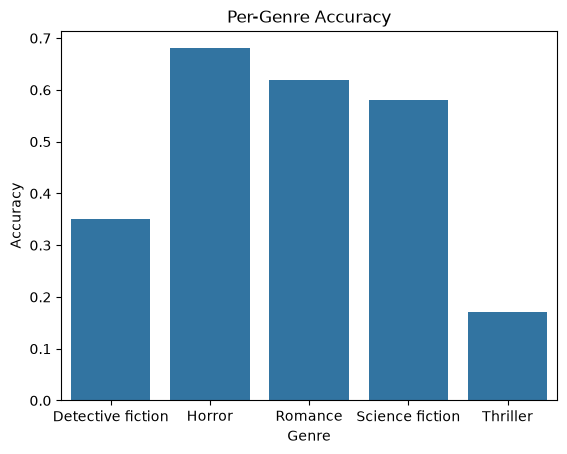

In [80]:
fig, ax = plt.subplots()
sns.barplot(data=genre_acc, x="true_genre", y="acc", ax=ax)
ax.set(title="Per-Genre Accuracy", xlabel="Genre", ylabel="Accuracy")
plt.show()

In [81]:
letters = list("ABCDE")
confusion_matrix = (
    pd.crosstab(y_true, y_pred).reindex(columns=letters, index=letters)
)

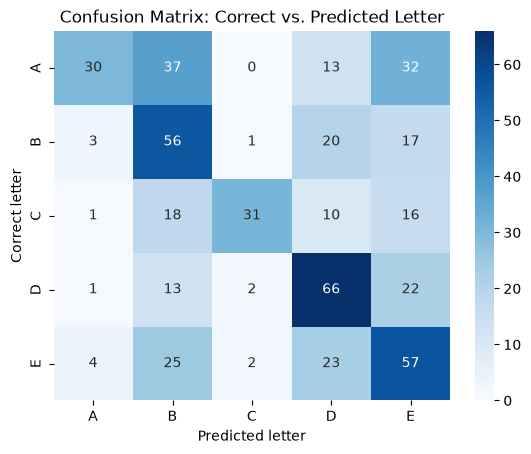

In [82]:
fig, ax = plt.subplots()
sns.heatmap(confusion_matrix, cmap="Blues", annot=True, fmt="d", ax=ax)
ax.set(
    title="Confusion Matrix: Correct vs. Predicted Letter",
    xlabel="Predicted letter",
    ylabel="Correct letter",
)
plt.show()

In [83]:
LETTERS = list("ABCDE")

def letter_bias(true_col, pred_col):
    """Compare observed vs. expected wrong-letter choices.

    Parameters
    ----------
    true_col : pd.Series
        Correct letters
    pred_col : pd.Series
        Predicted letters

    Returns
    -------
    pd.DataFrame
        Per-letter excess_share: positive means the model overuses this letter
        when wrong, negative means it avoids it
    """
    confusion_matrix = (
        pd.crosstab(true_col, pred_col)
        .reindex(index=LETTERS, columns=LETTERS, fill_value=0)
    )

    # Keep only wrong predictions
    off = confusion_matrix.values.copy()
    np.fill_diagonal(off, 0)
    off = pd.DataFrame(off, index=LETTERS, columns=LETTERS)

    # Observed: how often each letter is chosen when wrong. Expected: each
    # row's errors spread evenly over the other k-1 letters
    k = len(LETTERS)
    observed = off.sum(axis=0)
    row_errors = off.sum(axis=1)
    total_errors = row_errors.sum()
    expected = (total_errors - row_errors) / (k - 1)

    bias = pd.DataFrame({"observed": observed, "expected": expected})

    if total_errors > 0:
        bias["observed_share"] = bias["observed"] / total_errors
        bias["expected_share"] = bias["expected"] / total_errors
    else:
        bias["observed_share"] = 0.0 
        bias["expected_share"] = 0.0

    bias["excess_share"] = bias["observed_share"] - bias["expected_share"]

    return bias.reset_index(names="predicted_letter")

In [84]:
bias = letter_bias(y_true, y_pred)

g = sns.catplot(
    data=bias,
    kind="bar",
    x="predicted_letter",
    y="excess_share",
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.refline(y=0, linestyle="--", color="black")
g.set_axis_labels("Predicted letter", "Observed share - Expected share")
g.fig.suptitle("Excess Wrong-Answer Share by Letter", y=1.05)
plt.show()

NameError: name 'FACET_HEIGHT' is not defined

In [85]:
letter_bias_score = 0.5 * bias["excess_share"].abs().sum()
print(f"Overall letter-bias score: {letter_bias_score:.3f}")

Overall letter-bias score: 0.324


In [86]:
genre_layer_summary = (
    logit_lens
    .groupby(["genre", "layer"], as_index=False)
    .agg(
        correct_margin=("correct_margin", "mean"),
    )
)

In [87]:
g = sns.relplot(
    data=genre_layer_summary,
    kind="line",
    x="layer",
    y="correct_margin",
    col="genre",
    col_wrap=2,
    marker="o",
    facet_kws={"sharey": True},
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.refline(y=0, linestyle="--", color="black")
g.set_axis_labels("Layer", "Correct margin")
g.set_titles("{col_name}")
g.fig.suptitle("Layer-wise Correct-Answer Margins by Genre", y=1.05)
plt.show()

NameError: name 'FACET_HEIGHT' is not defined